## Neural Computation
## Excersise 01: Computational function of biological units
<br><br>
Wiktor Młynarski<br>
*LMU Biology*<br>
mlynarski@bio.lmu.de

### 1. Simulation of the Izhikevich Neuron Model
<br>
<br>
The Izhikevich model simplifies the famous Hodgkin-Huxley model of neural spiking. It describes  a dynamic relationship between different biophysical parameters - capacitance, conductantces, currents and voltages - all of them depending on biological details and structure of the neuron. The Izhikevich model can be used to simulate a variety of neurons from different regions - the cortex, hippocampus etc, and to capture the repertoire of their activity. It is described by four parameters $a, b, c, d$, whose biophysical meaning we can ommit for now.
<br>
<br>

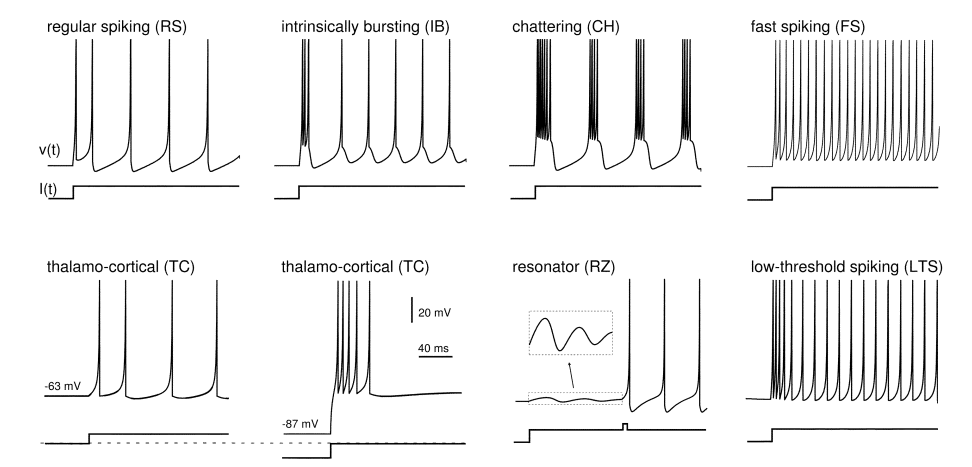

_Examples of diverse behaviors of the Izhikevich neuron model (figure taken from [1]) ._
<br><br>
Below is an implementation of the Izhikevich neuron model. Have a close look at the code to get a rough understanding of what is simulated and how.
<br>
<br>
Literature:<br>
<br>
[1] Izhikevich EM *Simple model of spiking neurons*, 2003, http://izhikevich.org/publications/spikes.pdf<br>

[2] Weber A, Pillow J, *Capturing the Dynamical Repertoire of Single Neurons
with Generalized Linear Models*, 2017,
http://pillowlab.princeton.edu/pubs/Weber17_IzhikevichGLM_NC.pdf

In [1]:
#function which simulates the Izhikevich neuron
def simulate_izhikevich_neuron(a, b, c, d, I_max=14, dt=0.01, n_t=50000):
    # --- Inputs: ---
    # a, b, c, d - parameters of the neuron
    # I_max - maximal value of the input current
    # dt - numerical integration step (in ms)
    # n_t - total number of simulation steps
    
    # --- Outputs: ---
    # v - simulated membrane potential
    # u - simulated "recovery variable"
    # spikes - a binary vector indicating in which time-bin a spike occured
    # spike_times - times of individual spikes
    # I - trajectory of the input current to the neuron
    # t_v - time vector
    
    # --- generate input ---
    I = np.zeros(n_t)
    t_start = int(0.2*n_t)
    t_stop = int(0.8*n_t)
    I[t_start:t_stop] = I_max

    # --- generate time vector ---
    T = dt * n_t #[ms]
    t_v = np.linspace(0, T, n_t)

    # --- allocate output variables ---
    #voltage membrane of the neuron
    v = np.zeros(n_t)
    
    #an auxiliary "recovery variable"
    u = np.zeros(n_t)
    
    #a binary vector indicating whether a spike occured at a given time bin
    spikes = np.zeros(n_t)

    # --- set initial conditions of the simulation ---
    v[0] = -70
    u[0] = -10

    # --- simulate ---
    for t in range(0, n_t-1):     
        #compute derivatives
        dvdt = 0.04*v[t]**2 + 5*v[t] + 140 - u[t] + I[t]    
        dudt = a*(b*v[t] - u[t])

        #update the variables using the Euler method
        v[t+1] = v[t] + dt * dvdt
        u[t+1] = u[t] + dt * dudt

        #if threshold exceeds spiking - record a spike
        if v[t+1] >= 30:
            #v[t+1] = 30
            spikes[t+1] = 1

            v[t+1] = c
            u[t+1] = u[t] + d

    #extract spike times
    spike_times = t_v[np.where(spikes)]
    
    return v, u, spikes, spike_times, I, t_v

**Excersise 1)** By varying biophysical parameters $a,b,c,d$ we can now genearate different behaviors of the neuron in response to the same stimulus - a square wave of the input current. These dynamic behaviors will span a range of biological phenomena, spiking, bursting etc. Play around with the parameters and try to observe different dynamics. *Hint* - sometimes you'll need to change the maximal value of the stimulus $I_{max}$ to observe interesting behavior. Save figures for reference if necessary. You may get some inspiration by looking at reference [1] as well as Fig. 6 and Table 1 in reference [2]. Keep in mind the question - could any of these dynamic behaviors _useful_ for solving some problem?

Text(0.5, 0, 'Time [ms]')

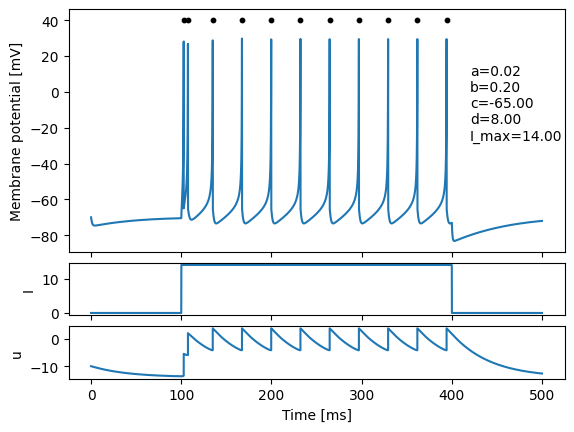

In [2]:
import numpy as np
from matplotlib import pyplot as plt

import warnings
warnings.filterwarnings('ignore')

#length of simulation step in ms
d_t = 0.01

#total number of simulation steps
n_t = 50000

#neuron parameters
a = 0.02
b = 0.2
c = -65
d = 8

#input parameters
I_max = 14

#run the simulation with the desired parameters
v, u, spikes, spike_times, I, t_v = simulate_izhikevich_neuron(a, b, c, d, I_max, d_t, n_t)

#plot results of the simulation
plt.figure()
plt.subplot(6,1,(1,4))
plt.plot(t_v, v)
plt.scatter(spike_times, np.ones(spike_times.shape) * 40, 10, 'k')
plt.ylabel('Membrane potential [mV]')
plt.text(420, v.min() + 0.5*(v.max()-v.min()), 'a=%.2f\nb=%.2f\nc=%.2f\nd=%.2f\nI_max=%.2f' % (a, b, c, d, I_max))
plt.subplot(6,1,5)
plt.plot(t_v, I)
plt.ylabel('I')
plt.subplot(6,1,6)
plt.plot(t_v, u)
plt.ylabel('u')
plt.xlabel('Time [ms]')

### 2. Defining a function of a neuron
<br>
<br>
Biophysical models such as the Izikievich model do not address the question - what computations could be performed by a neuron with different parameters? Which function can it perform?
<br>
<br>
To quantify computation we need something extra. Let's consider a  simple scenario, where we desire the neuron to generate some specific sequence of spikes in response to a steady input (as above). We will define a *utility function* $U(t)$, which will be equal to $1$ at times when we need the neuron to spike, and $-1$ when it needs to be silent. We can now compute the average utility per spike of a spike sequence: $\bar{U}(t_1, \ldots, t_n) = \frac{1}{n} \sum_{i=1}^n U(t_i)$.
<br>
<br>
Such average utility can be now used to identify biophysical parameters $a,b,c,d$ which will generate a useful computation! We just need to find parameters, which generate a high value of the average utility $\bar{U}$ of a spike sequence $(t_1, \ldots, t_n)$. Below is an example of a utility function for detecting onsets of the input.
<br>
<br>
Question - what kind of computation can not be quantified with such utility functions? What are it's drawbacks?

Text(0.5, 0, 'Time [ms]')

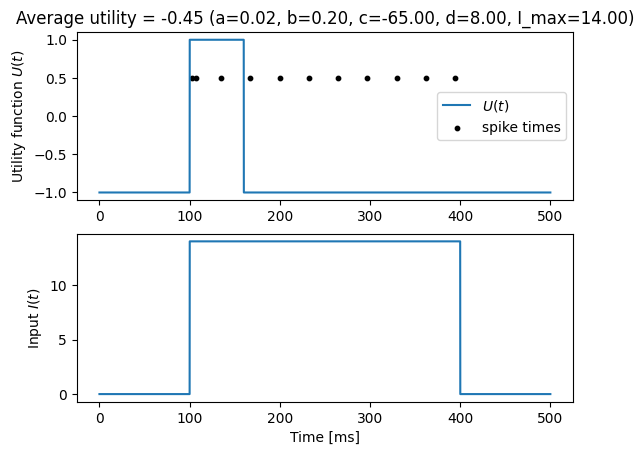

In [3]:
#mask defining when the neuron should generate a desired output

#utility for onset detection
t_start = int(0.2*n_t)
utility = np.zeros(n_t) - 1
utility[t_start:t_start+int(0.6*t_start)] = 1

#compute average utility per spike
average_utility = np.mean(utility[np.where(spikes)])

#plot
plt.figure()
plt.subplot(2,1,1)
plt.plot(t_v, utility, label='$U(t)$')
plt.ylabel('Utility function $U(t)$')
plt.scatter(spike_times, np.ones(spike_times.shape) * 0.5, 10, 'k', label='spike times')
plt.legend()
plt.title('Average utility = %.2f (a=%.2f, b=%.2f, c=%.2f, d=%.2f, I_max=%.2f)' % (average_utility, a, b, c, d, I_max))
plt.subplot(2,1,2)
plt.plot(t_v, I)
plt.ylabel('Input $I(t)$')
plt.xlabel('Time [ms]')



**Excersise 2 -  Optimizing neural parameters to perform computation - (onset detection)**<br> By manipulating parameters of the neuron (and potentially input amplitude)  find a setting which detects onsets, that is signals the beginning of the stimulus. Such neuron could serve an imporant function for the organism - for example to signal that light intensity has changed in the environment. We can measured how well does a neuron perform this computation with the onset-detection utility function. Can you identify more than one way to implement onset detection with a biophysical neuron? *Hint* - have a look at references provided above.

In [27]:
def onset_utility(n_t=n_t):
    """Utility U(t): +1 in the onset window (100-160 ms), -1 elsewhere."""
    t_start = int(0.2 * n_t)
    utility = np.zeros(n_t) - 1
    utility[t_start:t_start + int(0.6 * t_start)] = 1
    return utility


def average_utility(spikes, utility):
    """Mean of U(t) over spike times.
    Wrapped so it can be reused for every parameter set; returns NaN if there are no spikes.
    """
    idx = np.where(spikes)[0]
    return np.nan if len(idx) == 0 else utility[idx].mean()



In [19]:

import itertools

grid = itertools.product(
    [0.02, 0.05, 0.1],        # a
    [0.2, 0.25, 0.3, 0.4],    # b
    [-65, -55],               # c
    [0, 2, 6, 8],             # d
    [0.5, 1, 1.5, 2, 3, 4, 8, 14],  # I_max
)

def grid_search(utility, grid):
    
    results = []
    for a, b, c, d, I_max in grid:
        _, _, spikes, _, _, _ = simulate_izhikevich_neuron(a, b, c, d, I_max, d_t, n_t)
        U = average_utility(spikes, utility)
        if not np.isnan(U):
            results.append((U, int(spikes.sum()), a, b, c, d, I_max))
    results.sort(key=lambda r: (-r[0], r[1]))
    return results


In [20]:
# Two different mechanisms that both reach the maximal utility of 1.0 (found with grid_search).

SOLUTIONS = {
    "A: phasic spiking (weak I, b=0.25)": dict(a=0.02, b=0.25, c=-65, d=6, I_max=0.5),
    "B: one spike, then adaptation (strong I)": dict(a=0.02, b=0.2, c=-65, d=6, I_max=3),
}

BASELINE = dict(a=0.4, b=0.2, c=-65, d=6, I_max=14)

Baseline (a=0.4, I=14) -> 68 spike(s), average utility = -0.59
A: phasic spiking (weak I, b=0.25) -> 1 spike(s), average utility = 1.00
B: one spike, then adaptation (strong I) -> 1 spike(s), average utility = 1.00


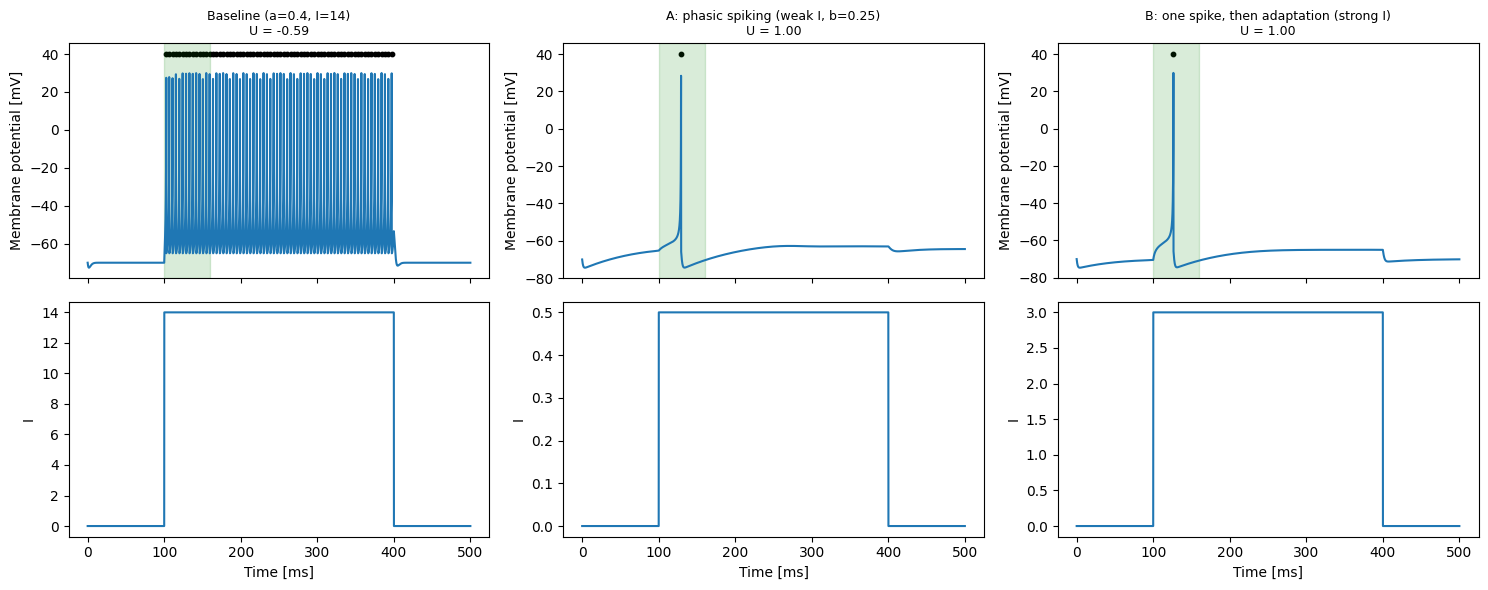

In [ ]:
def main(run_search=False):
    """Simulate baseline + both solutions
    run_search=True also runs grid_search and prints the top 10 (slow, so off by default).
    """
    utility = onset_utility()

    if run_search:
        print("Top 10 parameter sets from the grid search (U, n_spikes, a, b, c, d, I_max):")
        for r in grid_search(utility, grid)[:10]:
            print("  ", r)

    cases = {"Baseline (a=0.4, I=14)": BASELINE, **SOLUTIONS}
    fig, axes = plt.subplots(2, len(cases), figsize=(5 * len(cases), 6), sharex=True)
    for k, (name, p) in enumerate(cases.items()):
        v, u, spikes, spike_times, I, t_v = simulate_izhikevich_neuron(
            p["a"], p["b"], p["c"], p["d"], p["I_max"], d_t, n_t)
        U = average_utility(spikes, utility)
        print("%s -> %d spike(s), average utility = %.2f" % (name, len(spike_times), U))

        axes[0, k].plot(t_v, v)
        axes[0, k].scatter(spike_times, np.full(spike_times.shape, 40), 10, "k")
        axes[0, k].axvspan(100, 160, color="g", alpha=0.15)  # green = onset window where U=+1 (spikes here are good)
        axes[0, k].set_title("%s\nU = %.2f" % (name, U), fontsize=9)
        axes[0, k].set_ylabel("Membrane potential [mV]")
        axes[1, k].plot(t_v, I)
        axes[1, k].set_ylabel("I")
        axes[1, k].set_xlabel("Time [ms]")
    fig.tight_layout()
    fig.savefig("exercise_02_onset_detection.png", dpi=120)
    plt.show()

if __name__ == "__main__":
    main(run_search=False)

**Excersise 3 - robustness of computational function to biological noise**<br>The Izhikevich model is deterministic, i.e. it will generate the same exact sequence of spikes when presented with the same input. What if the neuron was noisy? How would that affect the performance of the onset detection? Add random noise to spikes, by jittering spike times. How does the neuron perform with the increasing level of noise? Could it be improved using different settings

In [8]:

WINDOW = (100.0, 160.0)  # onset window in ms where U = +1
T_MAX = d_t * n_t        # simulation length in ms


def jitter_spike_times(spike_times, sigma, rng):
    """Gaussian noise (std sigma ms) to each spike time; keep times inside the recording.
    jittering spike times.
    """
    noisy = spike_times + rng.normal(0.0, sigma, size=spike_times.shape)
    return np.clip(noisy, 0.0, T_MAX - d_t)

def utility_of_times(spike_times, utility):
    """Average utility of a list of spike times (ms).
    Needed because jittered times no longer sit on the 0/1 `spikes` vector used here,
    so we look U(t) up directly at the (rounded) time bin. NaN if there are no spikes.
    """
    if len(spike_times) == 0:
        return np.nan
    idx = np.rint(spike_times / d_t).astype(int).clip(0, len(utility) - 1)
    return utility[idx].mean()

def noisy_utility(spike_times, sigma, utility, n_trials=1000, seed=0):
    """Mean and std of the average utility over n_trials random jitter draws.
    Averaging many trials is necessary because a single noisy draw is random.
    """
    rng = np.random.default_rng(seed)
    scores = [utility_of_times(jitter_spike_times(spike_times, sigma, rng), utility)
              for _ in range(n_trials)]
    return np.nanmean(scores), np.nanstd(scores)

In [9]:
import math



def expected_utility(spike_times, sigma):
    """Exact expected average utility for Gaussian jitter (no sampling noise).
    Each spike scores +1 with probability P(in window) and -1 otherwise, so its expected utility is
    2*P - 1. Used as a smooth, deterministic objective for tuning parameters (see tune_for_noise).
    Ignores clipping at the edges of the recording (negligible for spikes near 130 ms).
    """
    if len(spike_times) == 0:
        return np.nan
    s = max(sigma, 1e-6) * math.sqrt(2)
    p = [0.5 * (math.erf((WINDOW[1] - t) / s) - math.erf((WINDOW[0] - t) / s)) for t in spike_times]
    return float(np.mean(2 * np.array(p) - 1))

def tune_for_noise(sigma=25.0):
    """Fine search around solution A for parameters that maximise expected utility at `sigma`.
    Answers "could it be improved using different settings?". Jitter itself cannot be reduced, so
    the only lever is WHEN the neuron fires: the best spot is the window centre (130 ms), and fewer
    spikes outside the window are better. Returns (expected_U, params) sorted best first.
    """
    results = []
    for b in (0.24, 0.25, 0.26):
        for I_max in np.linspace(0.40, 0.60, 9):
            p = dict(a=0.02, b=b, c=-65, d=6, I_max=float(round(I_max, 3)))
            _, _, _, st, _, _ = simulate_izhikevich_neuron(p["a"], p["b"], p["c"], p["d"], p["I_max"], d_t, n_t)
            if len(st):
                results.append((expected_utility(st, sigma), len(st), st[0], p))
    results.sort(key=lambda r: -r[0])
    return results

Tuned for sigma=25 ms: expected U = 0.539, first spike at 129.2 ms, params = {'a': 0.02, 'b': 0.25, 'c': -65, 'd': 6, 'I_max': 0.5}
-> the best setting is already solution A (spike ~129 ms, window centre = 130 ms).

Average utility vs jitter sigma [ms]:
                                                0      1      2      5     10     15     20     25     30     40     50     60
Baseline (a=0.4, I=14)                      -0.59  -0.60  -0.60  -0.61  -0.63  -0.64  -0.66  -0.67  -0.68  -0.70  -0.72  -0.73
A: phasic spiking (weak I, b=0.25)           1.00   1.00   1.00   1.00   0.99   0.93   0.77   0.56   0.37   0.12  -0.08  -0.22
B: one spike, then adaptation (strong I)     1.00   1.00   1.00   1.00   0.99   0.91   0.75   0.55   0.38   0.11  -0.09  -0.22


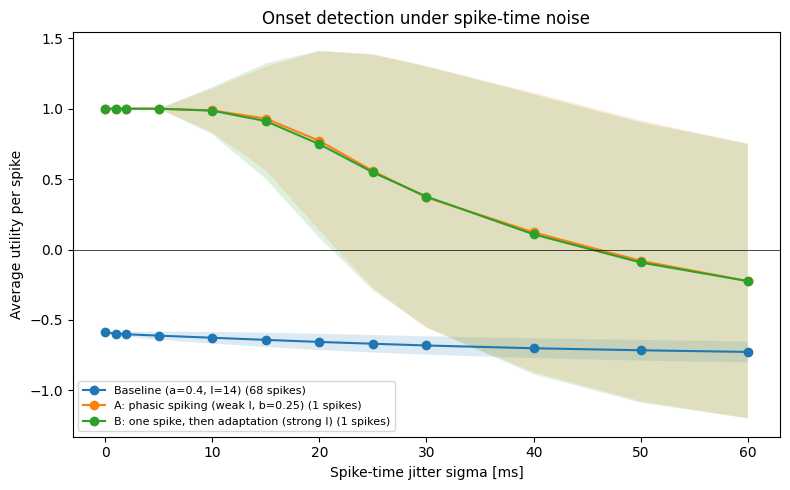

In [16]:
def main(run_tuning=True):
    utility = onset_utility()
    sigmas = np.array([0, 1, 2, 5, 10, 15, 20, 25, 30, 40, 50, 60])

    cases = {"Baseline (a=0.4, I=14)": BASELINE, **SOLUTIONS}
    if run_tuning:
        best = tune_for_noise()[0]
        print("Tuned for sigma=25 ms: expected U = %.3f, first spike at %.1f ms, params = %s"
              % (best[0], best[2], best[3]))
        # Only add a new curve if tuning actually found something different from solution A
        if best[3] not in SOLUTIONS.values():
            cases["C: A fine-tuned for noise"] = best[3]
        else:
            print("-> the best setting is already solution A (spike ~129 ms, window centre = 130 ms).")

    spike_times = {}
    for name, p in cases.items():
        _, _, _, st, _, _ = simulate_izhikevich_neuron(p["a"], p["b"], p["c"], p["d"], p["I_max"], d_t, n_t)
        spike_times[name] = st

    plt.figure(figsize=(8, 5))
    print("\nAverage utility vs jitter sigma [ms]:")
    print("%-42s" % "" + "".join("%7d" % s for s in sigmas))
    for name, st in spike_times.items():
        stats = [noisy_utility(st, s, utility) for s in sigmas]
        means = np.array([m for m, _ in stats])
        stds = np.array([sd for _, sd in stats])
        print("%-42s" % name + "".join("%7.2f" % m for m in means))
        plt.plot(sigmas, means, "o-", label="%s (%d spikes)" % (name, len(st)))
        plt.fill_between(sigmas, means - stds, means + stds, alpha=0.15)
    plt.axhline(0, color="k", lw=0.5)
    plt.xlabel("Spike-time jitter sigma [ms]")
    plt.ylabel("Average utility per spike")
    plt.title("Onset detection under spike-time noise")
    plt.legend(fontsize=8)
    plt.tight_layout()
    plt.savefig("exercise_03_noise_robustness.png", dpi=120)
    plt.show()

if __name__ == "__main__":
    main()

**Excersise 4 - Optimizing neural parameters to perform a custom computation**<br>
Now design your own utility function which would correspond to some meaningful task. It could be for example generation of a specific rhythm (a "clock"), integration of the input, detection of offsets, or even a very simple memory device. As before - yoy may use Fig 6 and Table 1 in Ref. [2] as an inspiration. Use your own utility function to identify one or more parameters settings which generate spiking activity. Can you find more than one solution?

In [22]:

grid = itertools.product(
    [0.02, 0.03, 0.1], 
    [0.2, 0.25, 0.26], 
    [-65, -60, -55], 
    [0, 2, 4, 6],
    [-20, -10, -5, -3, -2, -1, 1, 5])

WINDOW = (400.0, 460.0)  # ms; the input pulse ends at 400 ms

def offset_utility(n_t=n_t):
    """U(t) = +1 in WINDOW, -1 elsewhere."""
    utility = np.full(n_t, -1.0)
    utility[int(WINDOW[0] / d_t):int(WINDOW[1] / d_t)] = 1
    return utility


In [23]:
# Both are rebound spikes (hyperpolarising pulse, spike on release); 379 of 864 grid settings reach U=1.
SOLUTIONS = {
    "A: slow recovery, weak inhibition": dict(a=0.02, b=0.25, c=-65, d=0, I_max=-2),
    "B: fast recovery, strong inhibition": dict(a=0.1, b=0.26, c=-65, d=0, I_max=-10),
}

A: slow recovery, weak inhibition -> 1 spike(s) at [415.5] ms, U = 1.00
B: fast recovery, strong inhibition -> 1 spike(s) at [407.6] ms, U = 1.00


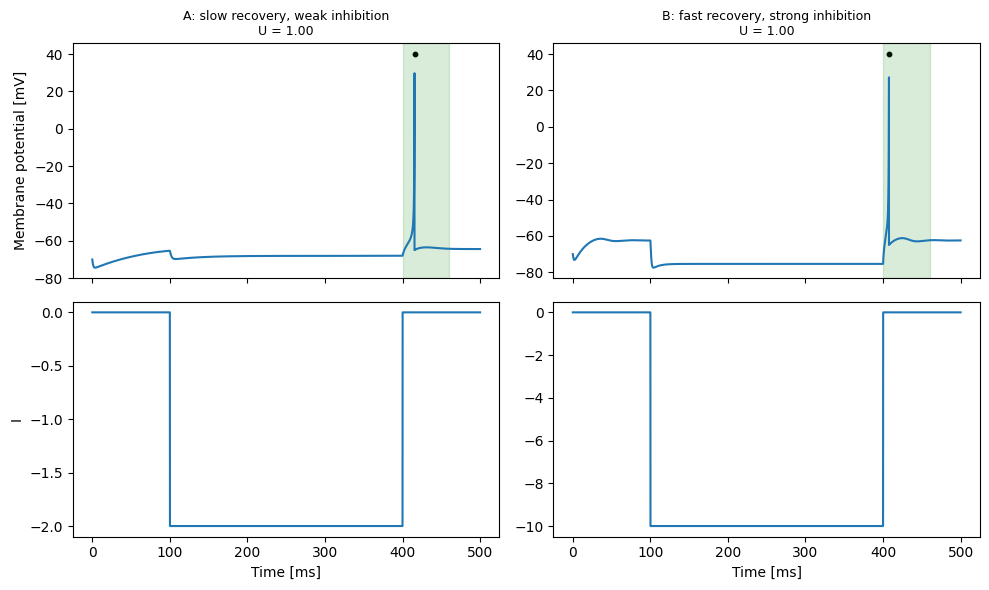

In [26]:
def main(run_search=False):
    utility = offset_utility()
    if run_search:
        for r in grid_search(utility, grid)[:15]:
            print(r)
        return

    fig, axes = plt.subplots(2, len(SOLUTIONS), figsize=(5 * len(SOLUTIONS), 6), sharex=True)
    for k, (name, p) in enumerate(SOLUTIONS.items()):
        v, _, spikes, st, I, t_v = simulate_izhikevich_neuron(p["a"], p["b"], p["c"], p["d"], p["I_max"], d_t, n_t)
        U = average_utility(spikes, utility)
        print("%s -> %d spike(s) at %s ms, U = %.2f" % (name, len(st), np.round(st[:5], 1), U))
        axes[0, k].plot(t_v, v)
        axes[0, k].scatter(st, np.full(st.shape, 40), 10, "k")
        axes[0, k].axvspan(*WINDOW, color="g", alpha=0.15)
        axes[0, k].set_title("%s\nU = %.2f" % (name, U), fontsize=9)
        axes[1, k].plot(t_v, I)
        axes[1, k].set_xlabel("Time [ms]")
    axes[0, 0].set_ylabel("Membrane potential [mV]")
    axes[1, 0].set_ylabel("I")
    fig.tight_layout()
    fig.savefig("exercise_04_offset_detection.png", dpi=120)
    plt.show()


if __name__ == "__main__":
    main(run_search=False)  # True redoes the (slow) parameter scan

**Excersise 5 - discussion** Based on the excersise you just did - what is the difference between the computational function of a system and the substrate it's implemented in? Can you identify the "Marr's levels of analysis" corresponding to different components of the simulations above (utilty function, neural parameters, spiking behavior etc)?